In [ ]:

from google.colab import files

uploaded = files.upload()


Saving kaggle.json to kaggle.json


In [ ]:

!kaggle --version
!kaggle datasets list -s salary


Kaggle CLI 2.0.2
You must authenticate before you can call the Kaggle API.
Follow the instructions to authenticate at: https://github.com/Kaggle/kaggle-cli/blob/main/docs/README.md#authentication


In [ ]:

!kaggle datasets download -d abhishek14398/salary-dataset-simple-linear-regression


Dataset URL: https://www.kaggle.com/datasets/abhishek14398/salary-dataset-simple-linear-regression
License(s): CC0-1.0
100% 457/457 [00:00<00:00, 1.06MB/s]



In [ ]:

!pip install --upgrade kaggle


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 3.6 MB/s eta 0:00:00
  Attempting uninstall: kaggle
    Found existing installation: kaggle 2.0.2
    Uninstalling kaggle-2.0.2:
      Successfully uninstalled kaggle-2.0.2


In [ ]:

!kaggle --version


Kaggle CLI 2.2.4


In [ ]:

!kaggle datasets download -d abhishek14398/salary-dataset-simple-linear-regression


Dataset URL: https://www.kaggle.com/datasets/abhishek14398/salary-dataset-simple-linear-regression
License(s): CC0-1.0
salary-dataset-simple-linear-regression.zip: Skipping, found more recently modified local copy (use --force to force download)


In [ ]:

import os
import glob

print("Current folder:", os.getcwd())
print("Files in current folder:", os.listdir("."))
print("ZIP files:", glob.glob("*.zip"))
print("CSV files:", glob.glob("**/*.csv", recursive=True))


Current folder: /content
Files in current folder: ['.config', 'salary-dataset-simple-linear-regression.zip', 'kaggle.json', 'sample_data']
ZIP files: ['salary-dataset-simple-linear-regression.zip']
CSV files: ['sample_data/california_housing_train.csv', 'sample_data/mnist_train_small.csv', 'sample_data/mnist_test.csv', 'sample_data/california_housing_test.csv']


In [ ]:

import zipfile
import os

zip_path = "/content/salary-dataset-simple-linear-regression.zip"
extract_path = "/content/salary_data"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Extracted successfully!")
print("Files:", os.listdir(extract_path))


Extracted successfully!
Files: ['Salary_dataset.csv']


In [ ]:

import pandas as pd
import glob

csv_files = glob.glob(
    "/content/salary_data/**/*.csv",
    recursive=True
)

print("CSV files found:", csv_files)

if csv_files:
    df = pd.read_csv(csv_files[0])
    print("\nFirst 5 rows:")
    display(df.head())
else:
    print("No CSV found. Check the extracted files.")


CSV files found: ['/content/salary_data/Salary_dataset.csv']

First 5 rows:


,Unnamed: 0,YearsExperience,Salary
0,0,1.2,39344.0
1,1,1.4,46206.0
2,2,1.6,37732.0
3,3,2.1,43526.0
4,4,2.3,39892.0


In [ ]:

print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nDataset information:")
df.info()


Shape: (30, 3)

Columns: ['Unnamed: 0', 'YearsExperience', 'Salary']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Unnamed: 0       30 non-null     int64  
 1   YearsExperience  30 non-null     float64
 2   Salary           30 non-null     float64
dtypes: float64(2), int64(1)
memory usage: 852.0 bytes


In [ ]:

# Check the dataset
print("Dataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

# Remove unnecessary index column, if present
df = df.loc[:, ~df.columns.str.contains("^Unnamed")]

# Remove duplicate rows
df = df.drop_duplicates()

# Remove rows with missing values
df = df.dropna()

print("\nCleaned dataset shape:", df.shape)
display(df.head())


Dataset shape: (30, 3)

Column names: ['Unnamed: 0', 'YearsExperience', 'Salary']

Missing values:
 Unnamed: 0         0
YearsExperience    0
Salary             0
dtype: int64

Duplicate rows: 0

Cleaned dataset shape: (30, 2)


,YearsExperience,Salary
0,1.2,39344.0
1,1.4,46206.0
2,1.6,37732.0
3,2.1,43526.0
4,2.3,39892.0


,YearsExperience,Salary
count,30.000000,30.000000
mean,5.413333,76004.000000
std,2.837888,27414.429785
min,1.200000,37732.000000
25%,3.300000,56721.750000
50%,4.800000,65238.000000
75%,7.800000,100545.750000
max,10.600000,122392.000000


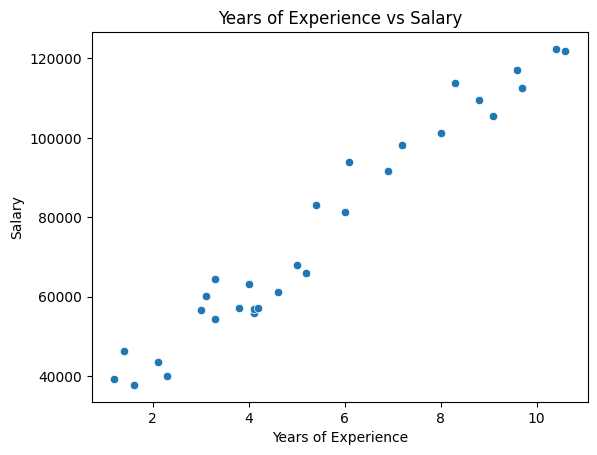

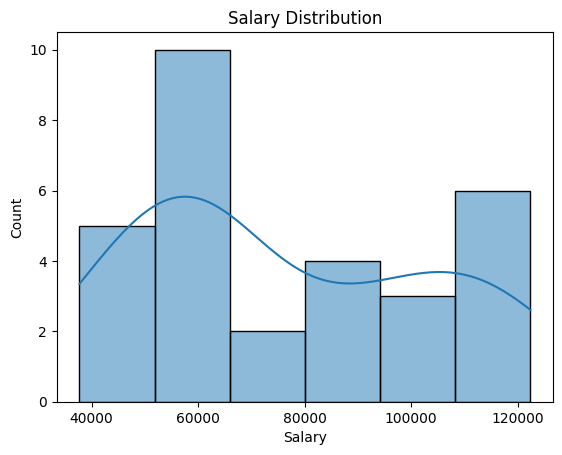

Correlation matrix:


,YearsExperience,Salary
YearsExperience,1.000000,0.978242
Salary,0.978242,1.000000


In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

# Statistical summary
display(df.describe())

# Scatter plot
sns.scatterplot(data=df, x="YearsExperience", y="Salary")
plt.title("Years of Experience vs Salary")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.show()

# Salary distribution
sns.histplot(data=df, x="Salary", kde=True)
plt.title("Salary Distribution")
plt.show()

# Correlation
print("Correlation matrix:")
display(df.corr(numeric_only=True))


In [ ]:

X = df[["YearsExperience"]]
y = df["Salary"]

print("Input feature (X):")
display(X.head())

print("Target variable (y):")
display(y.head())


Input feature (X):


,YearsExperience
0,1.2
1,1.4
2,1.6
3,2.1
4,2.3


Target variable (y):


,Salary
0,39344.0
1,46206.0
2,37732.0
3,43526.0
4,39892.0


In [ ]:

print("Dataset loaded:", "df" in globals())

if "df" in globals():
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    display(df.head())

print("Model trained:", "model" in globals())


Dataset loaded: True
Shape: (30, 2)
Columns: ['YearsExperience', 'Salary']


,YearsExperience,Salary
0,1.2,39344.0
1,1.4,46206.0
2,1.6,37732.0
3,2.1,43526.0
4,2.3,39892.0


Model trained: False


In [ ]:

# Feature Engineering

df["YearsExperienceSquared"] = df["YearsExperience"] ** 2

print(df.head())


   YearsExperience   Salary  YearsExperienceSquared
0              1.2  39344.0                    1.44
1              1.4  46206.0                    1.96
2              1.6  37732.0                    2.56
3              2.1  43526.0                    4.41
4              2.3  39892.0                    5.29


In [ ]:

X = df[["YearsExperience", "YearsExperienceSquared"]]
y = df["Salary"]

print("Features:")
display(X.head())

print("Target:")
display(y.head())


Features:


,YearsExperience,YearsExperienceSquared
0,1.2,1.44
1,1.4,1.96
2,1.6,2.56
3,2.1,4.41
4,2.3,5.29


Target:


,Salary
0,39344.0
1,46206.0
2,37732.0
3,43526.0
4,39892.0


In [ ]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (24, 2)
Testing data: (6, 2)


In [ ]:

from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

print("Model trained successfully!")


Model trained successfully!


In [ ]:

import pandas as pd

years = 1

new_person = pd.DataFrame({
    "YearsExperience": [years],
    "YearsExperienceSquared": [years ** 2]
})

predicted_salary = model.predict(new_person)

print(f"Predicted salary for {years} years of experience: {predicted_salary[0]:,.2f}")


Predicted salary for 1 years of experience: 35,000.14


NEW DATA SET

In [ ]:

import pandas as pd

data = pd.DataFrame({
    'YearsExperience': [1.1, 1.3, 1.5, 2.0, 2.2, 2.9, 3.0, 3.2, 3.2, 3.7,
                        3.9, 4.0, 4.0, 4.1, 4.5, 4.9, 5.1, 5.3, 5.9, 6.0,
                        6.8, 7.1, 7.9, 8.2, 8.7, 9.0, 9.5, 9.6, 10.3, 10.5],
    'Salary': [39343, 46205, 37731, 43525, 39891, 56642, 60150, 54445, 64445, 57189,
               63218, 55794, 56957, 57081, 61111, 67938, 66029, 83088, 81363, 93940,
               91738, 98273, 101302, 113812, 109431, 105582, 116969, 112635, 122391, 121872]
})

display(data.head())


,YearsExperience,Salary
0,1.1,39343
1,1.3,46205
2,1.5,37731
3,2.0,43525
4,2.2,39891


In [ ]:

data["YearsExperienceSquared"] = data["YearsExperience"] ** 2

display(data.head())


,YearsExperience,Salary,YearsExperienceSquared
0,1.1,39343,1.21
1,1.3,46205,1.69
2,1.5,37731,2.25
3,2.0,43525,4.00
4,2.2,39891,4.84


In [ ]:

X = data[["YearsExperience", "YearsExperienceSquared"]]
y = data["Salary"]

print("Input features (X):")
display(X.head())

print("Target (y):")
display(y.head())


Input features (X):


,YearsExperience,YearsExperienceSquared
0,1.1,1.21
1,1.3,1.69
2,1.5,2.25
3,2.0,4.00
4,2.2,4.84


Target (y):


,Salary
0,39343
1,46205
2,37731
3,43525
4,39891


In [ ]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 24
Testing samples: 6


In [ ]:

from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

print("Model trained successfully!")
print("Intercept:", model.intercept_)
print("Coefficients:", model.coef_)


Model trained successfully!
Intercept: 27285.66834967611
Coefficients: [8497.96546216   80.62084747]


In [ ]:

years = 1

new_person = pd.DataFrame({
    "YearsExperience": [years],
    "YearsExperienceSquared": [years ** 2]
})

predicted_salary = model.predict(new_person)

print(
    f"Predicted salary for {years} years of experience: "
    f"{predicted_salary[0]:,.2f}"
)


Predicted salary for 1 years of experience: 35,864.25
